In [ ]:
!apt-get update -qq
!apt-get install -y tesseract-ocr -qq
!pip install pytesseract opencv-python pandas matplotlib -q

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import re
from google.colab import files

In [ ]:
import glob
import os

# Mencari semua gambar ijazah di folder /content
file_ijazah = sorted(
    glob.glob("/content/*.jpg")
)

print("Jumlah ijazah:", len(file_ijazah))

for i, file in enumerate(file_ijazah, 1):
    print(i, os.path.basename(file))

Jumlah ijazah: 9
1 01_HighQuality_Enhanced.jpg
2 02_LowContrast.jpg
3 03_Blurred.jpg
4 04_HighNoise.jpg
5 05_LowResolution_Upsampled.jpg
6 06_Faded_Underexposed.jpg
7 07_ColorShift_WarmTint.jpg
8 08_JPEGCompression_Artifacts.jpg
9 09_CombinedDegradation.jpg


Jumlah ijazah: 9
1 01_HighQuality_Enhanced.jpg
2 02_LowContrast.jpg
3 03_Blurred.jpg
4 04_HighNoise.jpg
5 05_LowResolution_Upsampled.jpg
6 06_Faded_Underexposed.jpg
7 07_ColorShift_WarmTint.jpg
8 08_JPEGCompression_Artifacts.jpg
9 09_CombinedDegradation.jpg


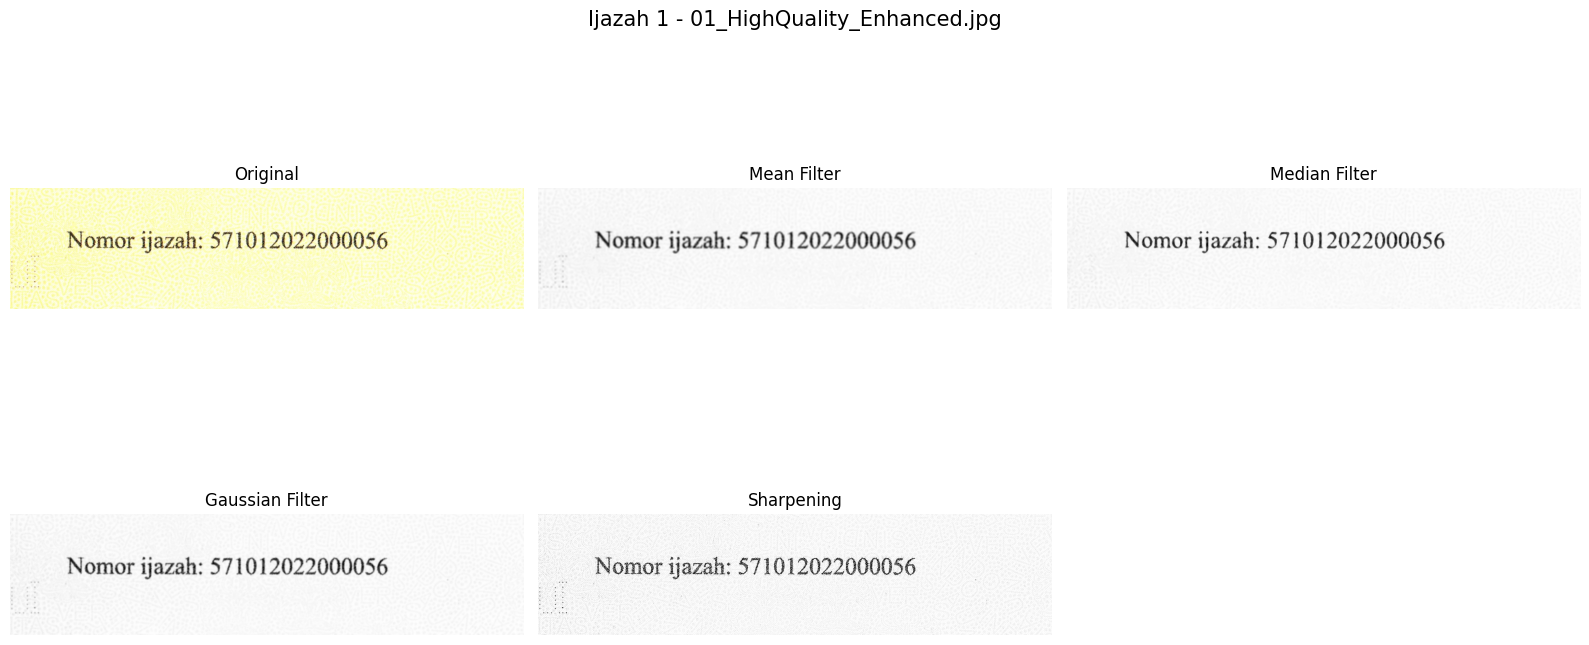

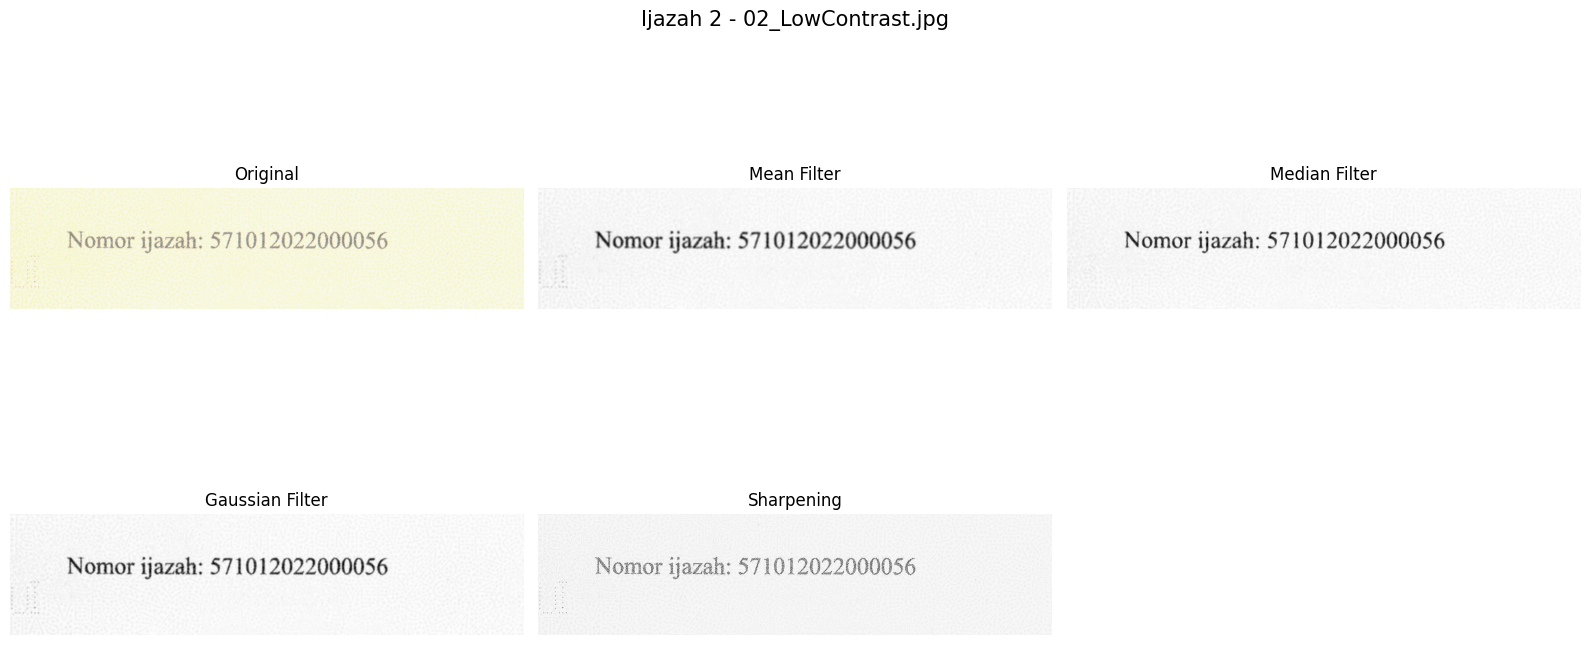

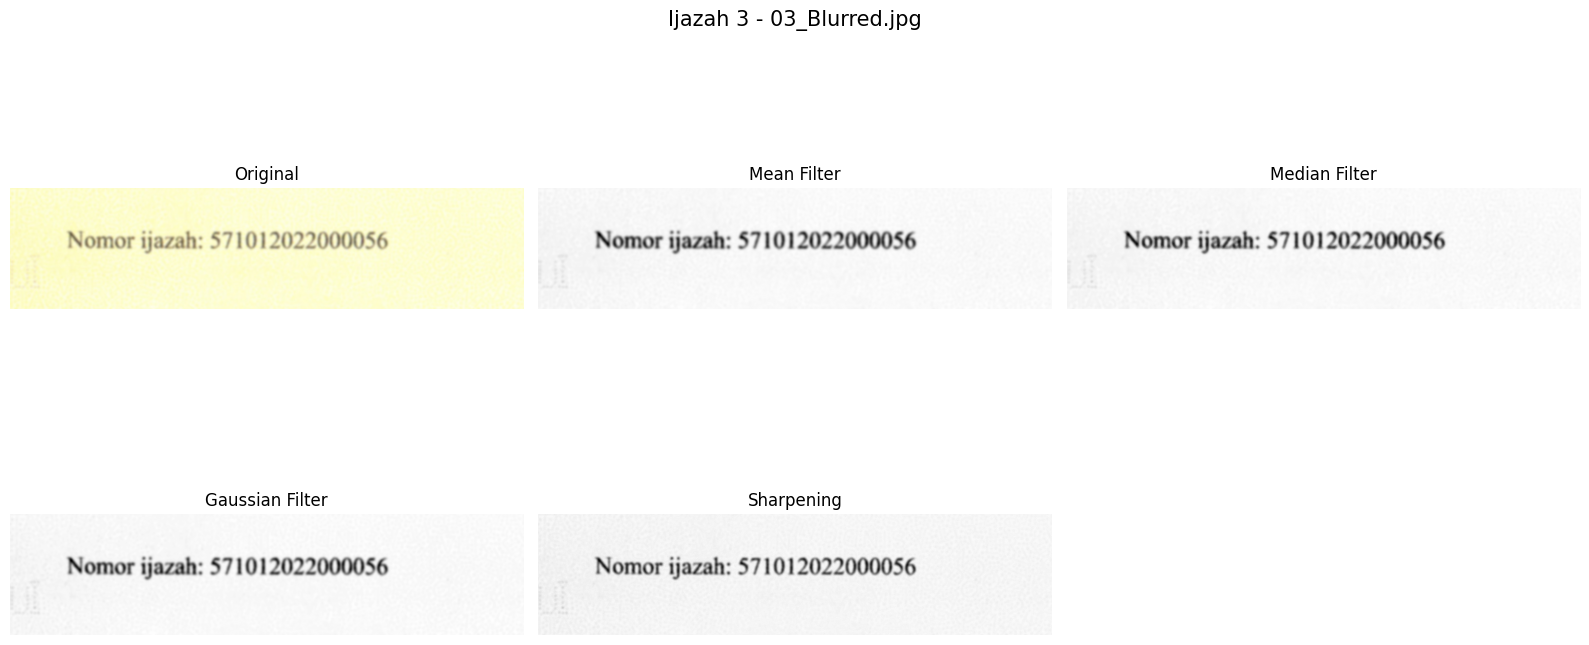

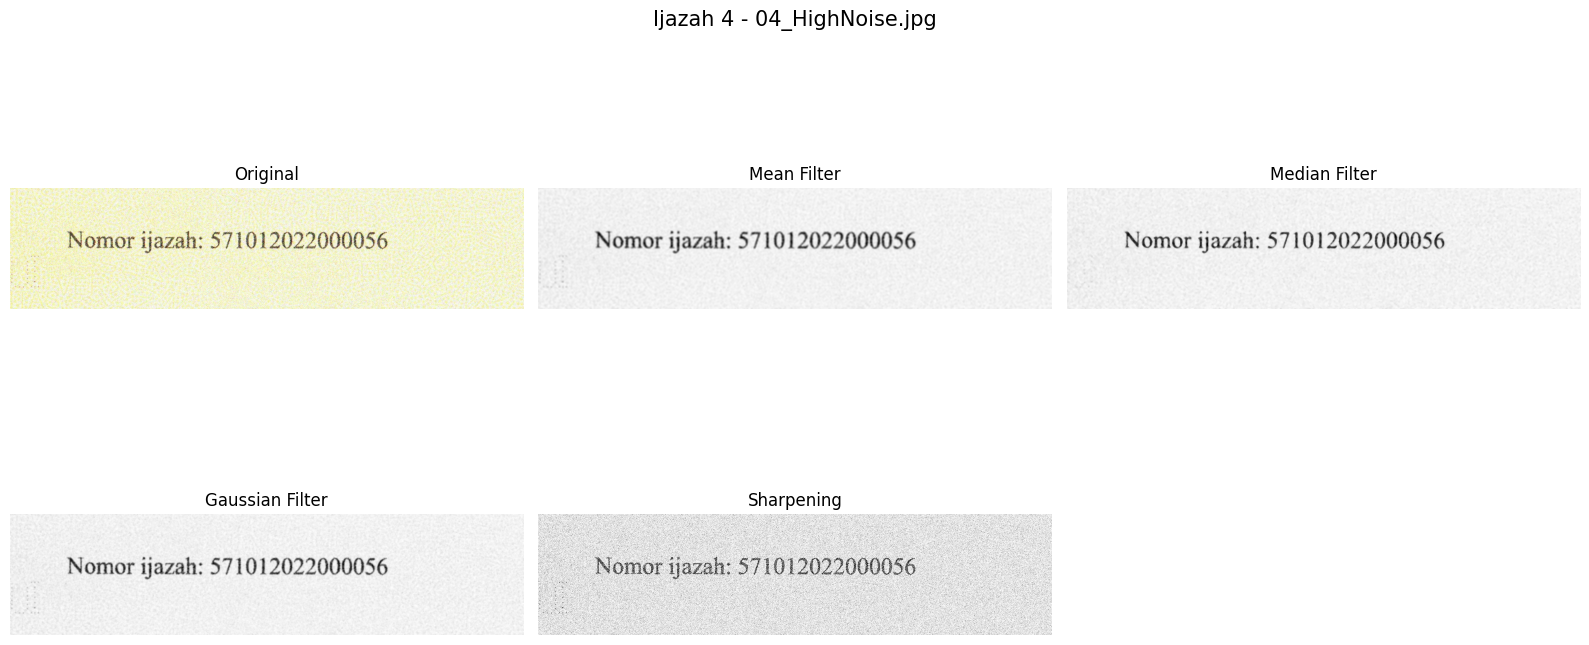

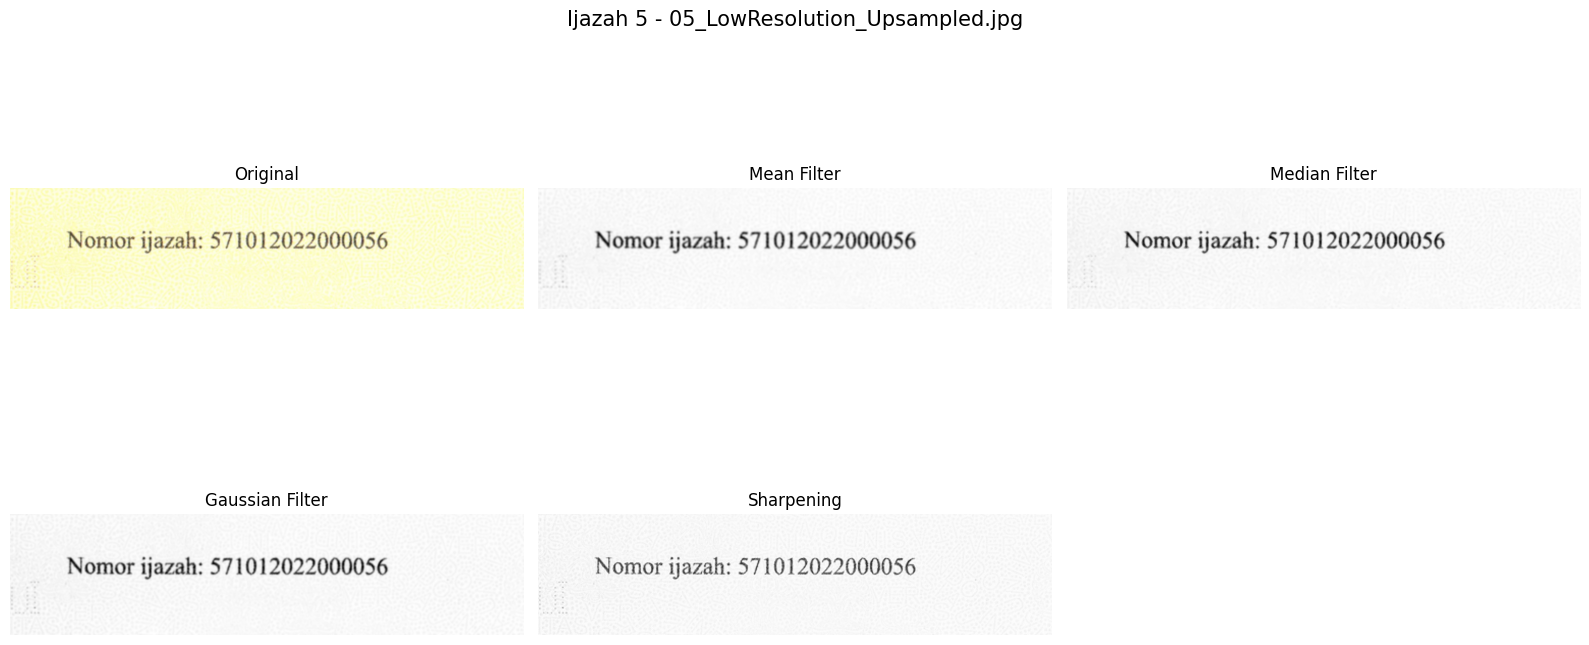

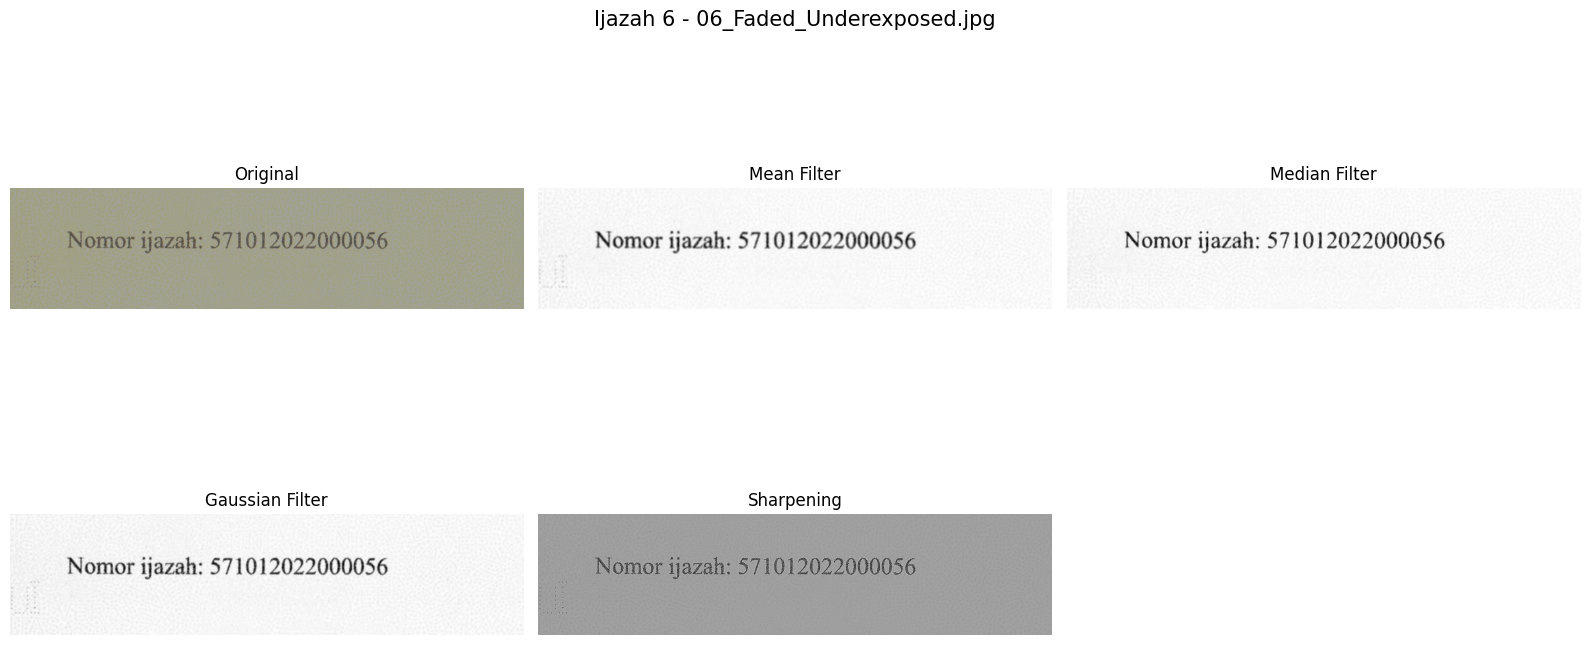

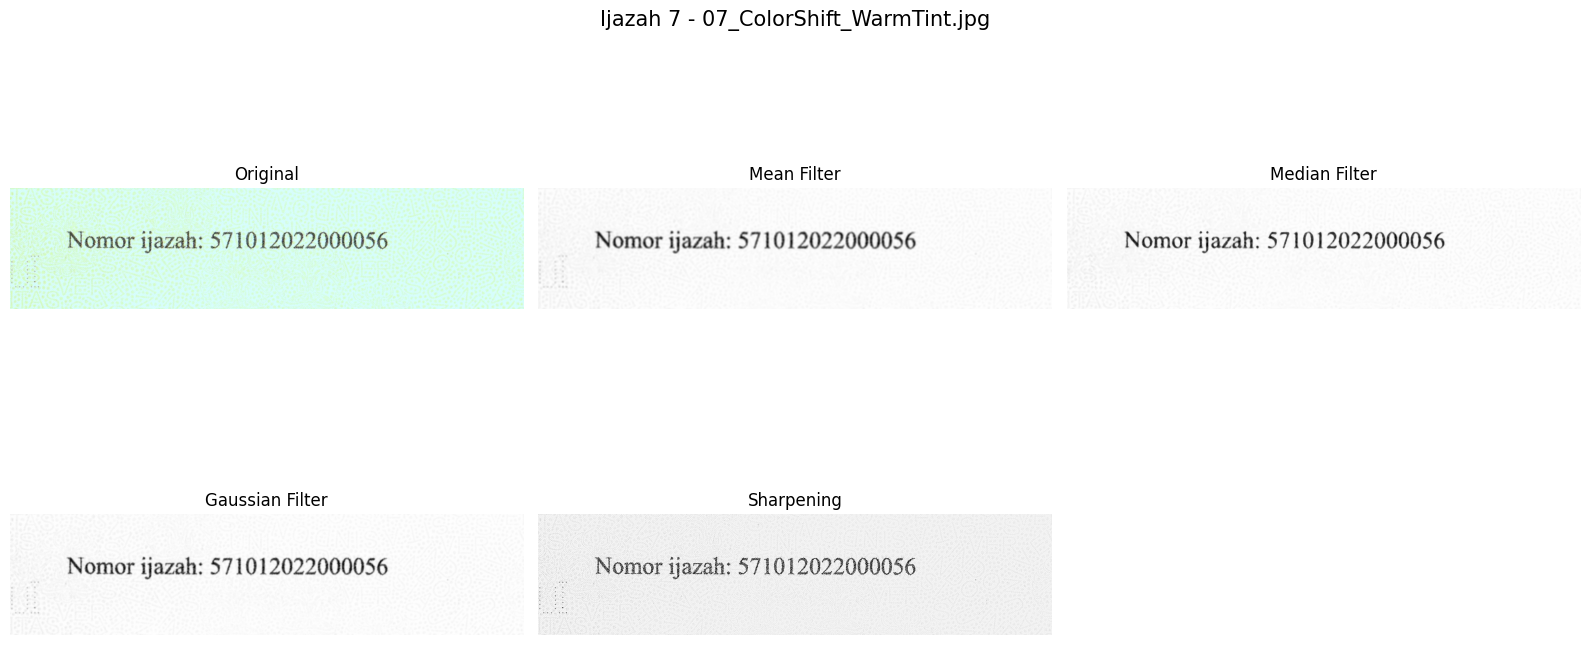

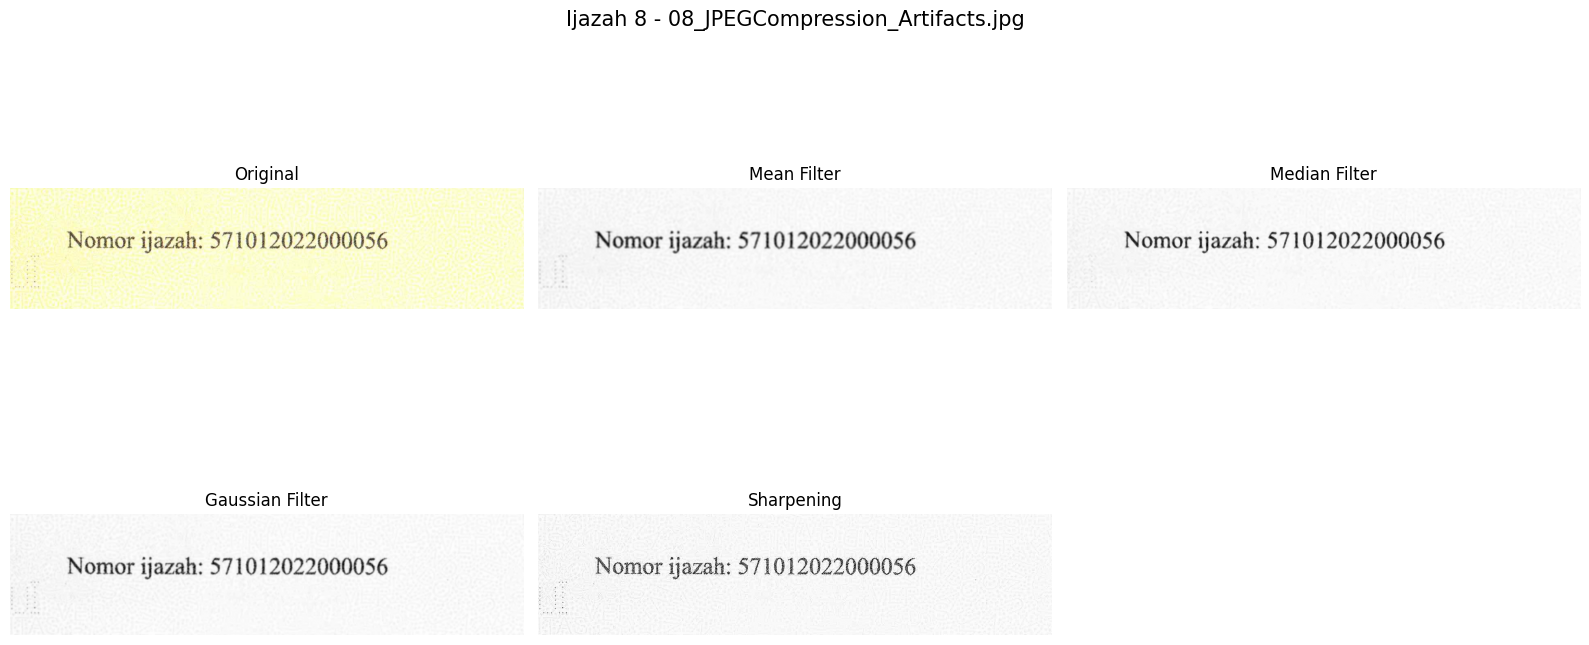

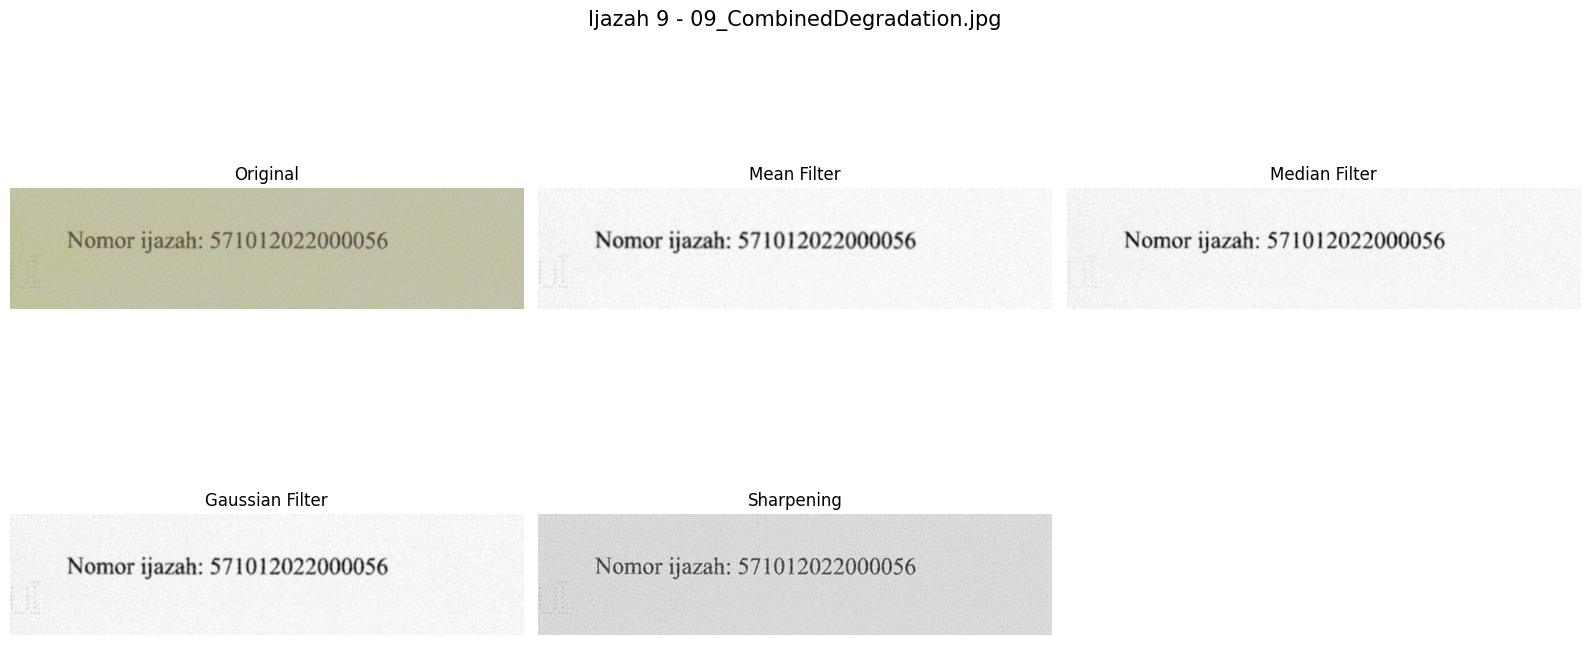

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# Ambil semua file JPG
file_ijazah = sorted(glob.glob("/content/*.jpg"))

print("Jumlah ijazah:", len(file_ijazah))

for i, file in enumerate(file_ijazah, 1):
    print(i, os.path.basename(file))

# Proses semua ijazah
for i, file in enumerate(file_ijazah, 1):

    # Baca gambar
    image = cv2.imread(file)

    # Putar 90 derajat searah jarum jam
    image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)

    tinggi, lebar = image.shape[:2]

    # Crop nomor ijazah
    x1 = int(lebar * 0.02)
    x2 = int(lebar * 0.38)
    y1 = int(tinggi * 0.87)
    y2 = int(tinggi * 0.99)

    # Original = bagian asli dari ijazah
    original = image[y1:y2, x1:x2]

    # Grayscale untuk proses filtering
    gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)

    # Mean Filter
    mean_filter = cv2.blur(gray, (5, 5))

    # Median Filter
    median_filter = cv2.medianBlur(gray, 5)

    # Gaussian Filter
    gaussian_filter = cv2.GaussianBlur(gray, (5, 5), 0)

    # Sharpening
    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ])

    sharpening = cv2.filter2D(gray, -1, kernel)

    # Tampilkan hasil
    plt.figure(figsize=(16, 8))

    # Original
    plt.subplot(2, 3, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("Original")
    plt.axis("off")

    # Mean
    plt.subplot(2, 3, 2)
    plt.imshow(mean_filter, cmap="gray")
    plt.title("Mean Filter")
    plt.axis("off")

    # Median
    plt.subplot(2, 3, 3)
    plt.imshow(median_filter, cmap="gray")
    plt.title("Median Filter")
    plt.axis("off")

    # Gaussian
    plt.subplot(2, 3, 4)
    plt.imshow(gaussian_filter, cmap="gray")
    plt.title("Gaussian Filter")
    plt.axis("off")

    # Sharpening
    plt.subplot(2, 3, 5)
    plt.imshow(sharpening, cmap="gray")
    plt.title("Sharpening")
    plt.axis("off")

    plt.suptitle(
        "Ijazah " + str(i) + " - " + os.path.basename(file),
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ==============================
# OCR 5 METODE
# ==============================

import re
import numpy as np
import pandas as pd
import pytesseract
from PIL import Image
import cv2
import os # Added os import
from IPython.display import display # Added display import

GROUND_TRUTH = "571012022000056"

def ocr(image):
    # Jika gambar berwarna, ubah ke grayscale
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Pastikan format gambar benar
    image = np.asarray(image, dtype=np.uint8)

    # Perbesar gambar
    image = cv2.resize(
        image,
        None,
        fx=3,
        fy=3,
        interpolation=cv2.INTER_CUBIC
    )

    # Pastikan array tersusun dengan benar
    image = np.ascontiguousarray(image)

    # Ubah ke PIL agar lebih stabil untuk Tesseract
    pil_image = Image.fromarray(image)

    try:
        hasil = pytesseract.image_to_string(
            pil_image,
            config="--psm 7 -c tessedit_char_whitelist=0123456789",
            timeout=10
        )
    except Exception as e:
        print("OCR error:", e)
        return ""

    # Ambil angka saja
    hasil = re.sub(r"[^0-9]", "", hasil)

    return hasil


def hitung_akurasi(hasil, target):
    benar = 0

    panjang = min(len(hasil), len(target))

    for i in range(panjang):
        if hasil[i] == target[i]:
            benar += 1

    akurasi = (benar / len(target)) * 100

    return benar, akurasi


# ==============================
# Generate hasil_pengolahan (replicating logic from previous cell for context)
# ==============================
hasil_pengolahan = {}

# Assuming file_ijazah is available from previous cells
# If not, you would need to define it here: file_ijazah = sorted(glob.glob("/content/*.jpg"))

for i, file in enumerate(file_ijazah, 1):
    image = cv2.imread(file)
    image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)

    tinggi, lebar = image.shape[:2]

    x1 = int(lebar * 0.02)
    x2 = int(lebar * 0.38)
    y1 = int(tinggi * 0.87)
    y2 = int(tinggi * 0.99)

    original = image[y1:y2, x1:x2]
    gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    mean_filter = cv2.blur(gray, (5, 5))
    median_filter = cv2.medianBlur(gray, 5)
    gaussian_filter = cv2.GaussianBlur(gray, (5, 5), 0)

    kernel = np.array([
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ])
    sharpening = cv2.filter2D(gray, -1, kernel)

    file_name_key = "Ijazah " + str(i) + " - " + os.path.basename(file)
    hasil_pengolahan[file_name_key] = {
        "Original": original,
        "Mean Filter": mean_filter,
        "Median Filter": median_filter,
        "Gaussian Filter": gaussian_filter,
        "Sharpening": sharpening
    }


# ==============================
# PROSES OCR SETIAP IJAZAH
# ==============================

for nama, data in hasil_pengolahan.items():

    print("\n" + "=" * 70)
    print("OCR:", nama)
    print("=" * 70)

    hasil_original = ocr(data["Original"])
    hasil_mean = ocr(data["Mean Filter"])
    hasil_median = ocr(data["Median Filter"])
    hasil_gaussian = ocr(data["Gaussian Filter"])
    hasil_sharpening = ocr(data["Sharpening"])

    semua_hasil = {
        "Original": hasil_original,
        "Mean Filter": hasil_mean,
        "Median Filter": hasil_median,
        "Gaussian Filter": hasil_gaussian,
        "Sharpening": hasil_sharpening
    }

    tabel = []

    for metode, hasil in semua_hasil.items():

        benar, akurasi = hitung_akurasi(
            hasil,
            GROUND_TRUTH
        )

        tabel.append({
            "Metode": metode,
            "Hasil OCR": hasil,
            "Karakter Benar": benar,
            "Akurasi": f"{akurasi:.2f}%"
        })

    df_ocr = pd.DataFrame(tabel)

    display(df_ocr)



OCR: Ijazah 1 - 01_HighQuality_Enhanced.jpg


,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Original,571012022000056,15,100.00%
1,Mean Filter,571012022000056,15,100.00%
2,Median Filter,571012022000056,15,100.00%
3,Gaussian Filter,571012022000056,15,100.00%
4,Sharpening,571012022000056,15,100.00%



OCR: Ijazah 2 - 02_LowContrast.jpg


,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Original,571012022000056,15,100.00%
1,Mean Filter,571012022000056,15,100.00%
2,Median Filter,571012022000056,15,100.00%
3,Gaussian Filter,571012022000056,15,100.00%
4,Sharpening,571012022000056,15,100.00%



OCR: Ijazah 3 - 03_Blurred.jpg


...

,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Original,571012022000056,15,100.00%
1,Mean Filter,571012022000056,15,100.00%
2,Median Filter,571012022000056,15,100.00%
3,Gaussian Filter,571012022000056,15,100.00%
4,Sharpening,571012022000056,15,100.00%



OCR: Ijazah 8 - 08_JPEGCompression_Artifacts.jpg


,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Original,571012022000056,15,100.00%
1,Mean Filter,571012022000056,15,100.00%
2,Median Filter,571012022000056,15,100.00%
3,Gaussian Filter,571012022000056,15,100.00%
4,Sharpening,571012022000056,15,100.00%



OCR: Ijazah 9 - 09_CombinedDegradation.jpg
OCR error: (-8, 'Image too small to scale!! (1x36 vs min width of 3) Line cannot be recognized!!')


,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Original,571012022000056,15,100.00%
1,Mean Filter,571012022000056,15,100.00%
2,Median Filter,571012022000056,15,100.00%
3,Gaussian Filter,1571012022000056,4,26.67%
4,Sharpening,,0,0.00%


In [ ]:
# Simpan hasil OCR ke Excel
df_ocr.to_excel('/content/hasil_ocr.xlsx', index=False)

# Download
from google.colab import files
files.download('/content/hasil_ocr.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================
# SIMPAN SEMUA HASIL OCR KE EXCEL
# ============================================

import pandas as pd
from google.colab import files
# No need to re-import cv2, numpy, pytesseract, re, Image as they are already imported and functions defined in previous cell
from IPython.display import display # Ensure display is imported

# Data hasil OCR dari seluruh gambar dan metode
data_ocr = []

# `hasil_pengolahan` is available from the previous cell's execution (PJoBpM-8Tb2e)
# `ocr` function is available from PJoBpM-8Tb2e
# `hitung_akurasi` function is available from PJoBpM-8Tb2e
# `GROUND_TRUTH` variable is available from PJoBpM-8Tb2e

for nama_ijazah_key, processed_image_data_for_methods in hasil_pengolahan.items():
    for metode, img_data_for_method in processed_image_data_for_methods.items():
        ocr_result = ocr(img_data_for_method)
        data_ocr.append({
            "Ijazah": nama_ijazah_key,
            "Metode": metode,
            "Hasil OCR": ocr_result
        })

# Buat DataFrame dari semua hasil OCR
df_all_ocr_results = pd.DataFrame(data_ocr)

# ============================================
# HITUNG KARAKTER BENAR DAN AKURASI
# ============================================

# Apply the accuracy calculation
df_all_ocr_results[["Karakter Benar", "Akurasi"]] = df_all_ocr_results[
    "Hasil OCR"
].apply(
    lambda x: pd.Series(hitung_akurasi(x, GROUND_TRUTH)) # Pass GROUND_TRUTH explicitly
)

# Format akurasi
df_all_ocr_results["Akurasi"] = df_all_ocr_results["Akurasi"].round(2)

# ============================================
# SIMPAN KE EXCEL
# ============================================

nama_excel = "/content/semua_hasil_ocr.xlsx"

df_all_ocr_results.to_excel(
    nama_excel,
    index=False
)

# ============================================
# TAMPILKAN HASIL
# ============================================

display(df_all_ocr_results)

# ============================================
# DOWNLOAD EXCEL
# ============================================

files.download(nama_excel)

OCR error: (-8, 'Image too small to scale!! (1x36 vs min width of 3) Line cannot be recognized!!')


,Ijazah,Metode,Hasil OCR,Karakter Benar,Akurasi
0,Ijazah 1 - 01_HighQuality_Enhanced.jpg,Original,571012022000056,15.0,100.00
1,Ijazah 1 - 01_HighQuality_Enhanced.jpg,Mean Filter,571012022000056,15.0,100.00
2,Ijazah 1 - 01_HighQuality_Enhanced.jpg,Median Filter,571012022000056,15.0,100.00
3,Ijazah 1 - 01_HighQuality_Enhanced.jpg,Gaussian Filter,571012022000056,15.0,100.00
4,Ijazah 1 - 01_HighQuality_Enhanced.jpg,Sharpening,571012022000056,15.0,100.00
5,Ijazah 2 - 02_LowContrast.jpg,Original,571012022000056,15.0,100.00
6,Ijazah 2 - 02_LowContrast.jpg,Mean Filter,571012022000056,15.0,100.00
7,Ijazah 2 - 02_LowContrast.jpg,Median Filter,571012022000056,15.0,100.00
8,Ijazah 2 - 02_LowContrast.jpg,Gaussian Filter,571012022000056,15.0,100.00
9,Ijazah 2 - 02_LowContrast.jpg,Sharpening,571012022000056,15.0,100.00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>